In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import svd
from numpy import zeros, diag
from sklearn.decomposition import PCA

In [3]:
os.chdir("D:/gus6e/Documents")
estudiantes = pd.read_csv("EjemploEstudiantes.csv", sep=";", decimal=",", index_col=0)
print("Base original de estudiantes:")
display(estudiantes)

Base original de estudiantes:


,Matematicas,Ciencias,Espanol,Historia,EdFisica
Lucia,7.0,6.5,9.2,8.6,8.0
Pedro,7.5,9.4,7.3,7.0,7.0
Ines,7.6,9.2,8.0,8.0,7.5
Luis,5.0,6.5,6.5,7.0,9.0
Andres,6.0,6.0,7.8,8.9,7.3
Ana,7.8,9.6,7.7,8.0,6.5
Carlos,6.3,6.4,8.2,9.0,7.2
Jose,7.9,9.7,7.5,8.0,6.0
Sonia,6.0,6.0,6.5,5.5,8.7
Maria,6.8,7.2,8.7,9.0,7.0


In [38]:
# Las categorías son propuestas de análisis, no etiquetas presentes en el CSV.
# Bajo: promedio < 7; Medio: 7 <= promedio < 8; Alto: promedio >= 8.
promedios = estudiantes.mean(axis=1)
etiquetas = pd.cut(promedios, bins=[-np.inf,7,8,np.inf], labels=["Bajo","Medio","Alto"], right=False)
resumen = estudiantes.copy()
resumen["Promedio"] = promedios
resumen["Grupo"] = etiquetas
display(resumen)
print("Cantidad por grupo:")
print(etiquetas.value_counts().reindex(["Bajo", "Medio", "Alto"], fill_value=0))

,Matematicas,Ciencias,Espanol,Historia,EdFisica,Promedio,Grupo
Lucia,7.0,6.5,9.2,8.6,8.0,7.86,Medio
Pedro,7.5,9.4,7.3,7.0,7.0,7.64,Medio
Ines,7.6,9.2,8.0,8.0,7.5,8.06,Alto
Luis,5.0,6.5,6.5,7.0,9.0,6.80,Bajo
Andres,6.0,6.0,7.8,8.9,7.3,7.20,Medio
Ana,7.8,9.6,7.7,8.0,6.5,7.92,Medio
Carlos,6.3,6.4,8.2,9.0,7.2,7.42,Medio
Jose,7.9,9.7,7.5,8.0,6.0,7.82,Medio
Sonia,6.0,6.0,6.5,5.5,8.7,6.54,Bajo
Maria,6.8,7.2,8.7,9.0,7.0,7.74,Medio


Cantidad por grupo:
Bajo     2
Medio    7
Alto     1
Name: count, dtype: int64


In [5]:
from numpy import array
from sklearn.decomposition import TruncatedSVD
A = estudiantes.to_numpy(dtype=float)
nombres = estudiantes.index.to_list()
materias = estudiantes.columns.to_list()
print("Matriz A: estudiantes (filas) x materias (columnas)")
print(A)

Matriz A: estudiantes (filas) x materias (columnas)
[[7.  6.5 9.2 8.6 8. ]
 [7.5 9.4 7.3 7.  7. ]
 [7.6 9.2 8.  8.  7.5]
 [5.  6.5 6.5 7.  9. ]
 [6.  6.  7.8 8.9 7.3]
 [7.8 9.6 7.7 8.  6.5]
 [6.3 6.4 8.2 9.  7.2]
 [7.9 9.7 7.5 8.  6. ]
 [6.  6.  6.5 5.5 8.7]
 [6.8 7.2 8.7 9.  7. ]]


In [6]:
from numpy import diag, zeros
from scipy.linalg import svd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
U, s, VT = svd(A, full_matrices=True)
Sigma = zeros((A.shape[0], A.shape[1]))
Sigma[:len(s), :len(s)] = diag(s)

In [8]:
print("Matriz U")
print(U)

Matriz U
[[-3.30904778e-01 -2.98442471e-01  1.95957496e-01 -5.49129984e-01
   3.41498230e-01  3.14150349e-02 -1.23395489e-01  1.44668847e-01
  -3.94701586e-01 -3.89792548e-01]
 [-3.20798129e-01  3.55909651e-01 -2.40201517e-01 -6.92729616e-02
   2.04368756e-01 -4.82498850e-01  2.12566116e-01 -5.29979923e-01
  -2.91960519e-01  1.48477689e-01]
 [-3.38871518e-01  2.14752307e-01 -1.01355072e-01  1.12970083e-02
   1.76844101e-01 -1.27934010e-01 -3.25968835e-01 -5.72499990e-02
   7.00049221e-01 -4.25915443e-01]
 [-2.86319969e-01 -3.47796853e-01 -4.56775340e-01  6.26123724e-01
   3.29136285e-01  7.19838459e-02 -5.36517108e-04  2.16809671e-01
  -1.85075729e-01 -4.01432467e-02]
 [-3.03747698e-01 -3.04664300e-01  2.89885414e-01  2.58403657e-01
  -5.09400304e-01 -1.58301296e-01 -4.86485858e-01 -3.39970765e-01
  -1.65040306e-01  8.72429330e-03]
 [-3.33011382e-01  3.96082489e-01  2.51606890e-02  5.94976208e-02
  -5.78210369e-02  8.06621727e-01  1.34546582e-02 -2.29782306e-01
  -1.43611096e-01 -2.149

In [9]:
print("Matriz Sigma")
print(Sigma)

Matriz Sigma
[[53.21335049  0.          0.          0.          0.        ]
 [ 0.          5.35631448  0.          0.          0.        ]
 [ 0.          0.          3.80560674  0.          0.        ]
 [ 0.          0.          0.          1.46904724  0.        ]
 [ 0.          0.          0.          0.          0.47799818]
 [ 0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.        ]]


In [10]:
print("Matriz VT")
print(VT)

Matriz VT
[[-0.40556463 -0.45759727 -0.46123811 -0.47103299 -0.43761787]
 [ 0.30388113  0.70497323 -0.20845983 -0.2165757  -0.56595801]
 [-0.00426062 -0.27229676  0.31573346  0.5963283  -0.6859601 ]
 [-0.56293162  0.34606734 -0.50555254  0.5444058   0.1066974 ]
 [-0.65288853  0.31576789  0.62332408 -0.28149203 -0.07909827]]


In [39]:
B = U.dot(Sigma.dot(VT))
print("Reconstrucción de A:")
print(B)

Reconstrucción de A:
[[7.  6.5 9.2 8.6 8. ]
 [7.5 9.4 7.3 7.  7. ]
 [7.6 9.2 8.  8.  7.5]
 [5.  6.5 6.5 7.  9. ]
 [6.  6.  7.8 8.9 7.3]
 [7.8 9.6 7.7 8.  6.5]
 [6.3 6.4 8.2 9.  7.2]
 [7.9 9.7 7.5 8.  6. ]
 [6.  6.  6.5 5.5 8.7]
 [6.8 7.2 8.7 9.  7. ]]


In [12]:
# Reducción a DOS dimensiones
n_elements = 2
UReduced2 = U[:, :n_elements]
print("U Reducida (2D)")
print(UReduced2)

U Reducida (2D)
[[-0.33090478 -0.29844247]
 [-0.32079813  0.35590965]
 [-0.33887152  0.21475231]
 [-0.28631997 -0.34779685]
 [-0.3037477  -0.3046643 ]
 [-0.33301138  0.39608249]
 [-0.31300374 -0.24404278]
 [-0.328788    0.47553197]
 [-0.27389698 -0.26452216]
 [-0.32638301 -0.10871076]]


In [13]:
SigmaReduced2 = Sigma[:2, :2]
print("Sigma Reducida (2D)")
print(SigmaReduced2)

Sigma Reducida (2D)
[[53.21335049  0.        ]
 [ 0.          5.35631448]]


In [14]:
VTReduced2 = VT[:2, :]
print("VT Reducida (2D)")
print(VTReduced2)

VT Reducida (2D)
[[-0.40556463 -0.45759727 -0.46123811 -0.47103299 -0.43761787]
 [ 0.30388113  0.70497323 -0.20845983 -0.2165757  -0.56595801]]


In [15]:
AReduced2 = UReduced2.dot(SigmaReduced2.dot(VTReduced2))
print("Matriz A aproximada con 2 componentes:")
print(AReduced2)

Matriz A aproximada con 2 componentes:
[[6.65563617 6.93068907 8.45496902 8.64041633 8.61053016]
 [7.50259774 9.15546106 7.47627701 7.62801112 6.39154032]
 [7.66288835 9.06253486 8.0774837  8.24477427 7.24032869]
 [5.61309793 5.65867129 7.41578628 7.58014066 7.72189396]
 [6.05941975 6.24591247 7.7953721  7.96693512 7.99698132]
 [7.83156613 9.60455223 7.73118336 7.88753689 6.55416982]
 [6.35785122 6.70021013 7.95486409 8.12861624 8.02875678]
 [7.86973795 9.80171752 7.53881312 7.68951159 6.21497236]
 [5.48053658 5.67061811 7.01789357 7.17215282 7.18015541]
 [6.86687283 7.53702066 8.13213661 8.30697925 7.93006916]]


In [16]:
T2 = UReduced2.dot(SigmaReduced2)
print("Coordenadas SVD (2D)")
print(T2)

Coordenadas SVD (2D)
[[-17.60855193  -1.59855173]
 [-17.07074326   1.90636402]
 [-18.03248887   1.15028089]
 [-15.23604486  -1.86290932]
 [-16.1634327   -1.6318778 ]
 [-17.7206514    2.12154237]
 [-16.65597775  -1.30716988]
 [-17.49591103   2.54709878]
 [-14.57497601  -1.41686385]
 [-17.36793336  -0.58228904]]


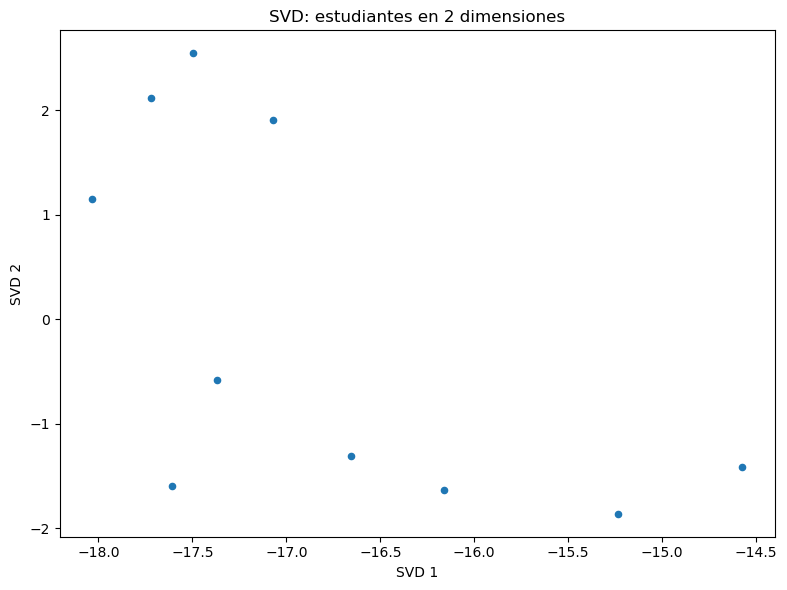

In [17]:
df = pd.DataFrame(T2, index=nombres, columns=["a","b"])
ax = df.plot(kind="scatter", x="a", y="b", figsize=(8,6), title="SVD: estudiantes en 2 dimensiones")
ax.set_xlabel("SVD 1"); ax.set_ylabel("SVD 2")
plt.tight_layout(); plt.show()

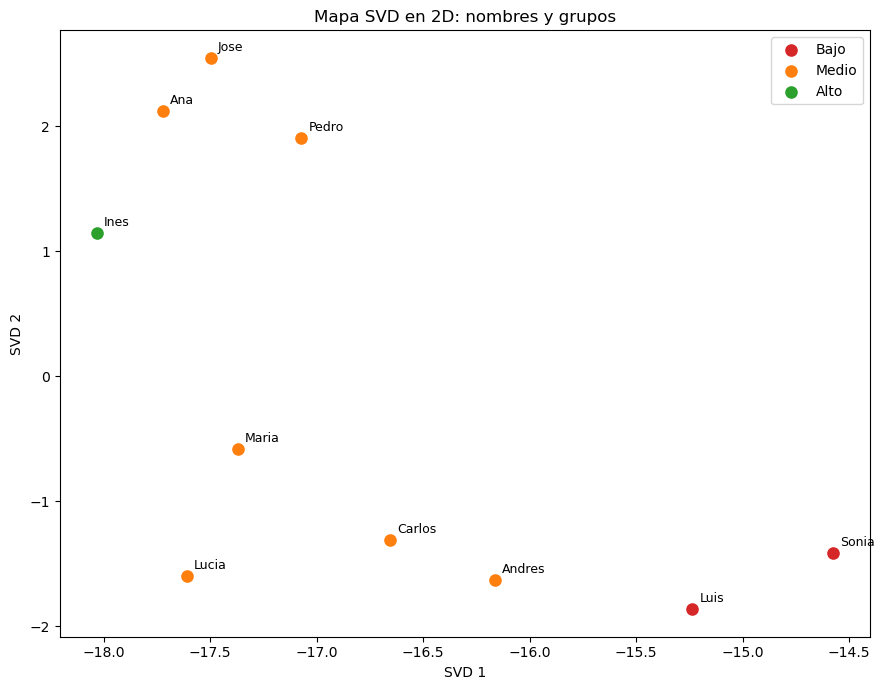

In [18]:
# Cada punto representa a un estudiante y su color representa el grupo por promedio.
fig, ax = plt.subplots(figsize=(9,7))
colores = {"Bajo":"tab:red", "Medio":"tab:orange", "Alto":"tab:green"}
for grupo in ["Bajo","Medio","Alto"]:
    mascara = (etiquetas.to_numpy() == grupo)
    ax.scatter(T2[mascara,0], T2[mascara,1], label=grupo, color=colores[grupo], s=65)
for i, nombre in enumerate(nombres):
    ax.annotate(nombre, (T2[i,0],T2[i,1]), xytext=(5,5), textcoords="offset points", fontsize=9)
ax.set_title("Mapa SVD en 2D: nombres y grupos")
ax.set_xlabel("SVD 1"); ax.set_ylabel("SVD 2"); ax.legend()
plt.tight_layout(); plt.show()

In [21]:
# Reducción a TRES dimensiones
n_elements = 3
UReduced3 = U[:, :n_elements]
SigmaReduced3 = Sigma[:n_elements, :n_elements]
VTReduced3 = VT[:n_elements, :]
AReduced3 = UReduced3.dot(SigmaReduced3.dot(VTReduced3))
print("Matriz A aproximada con 3 componentes")
print(AReduced3)

Matriz A aproximada con 3 componentes
[[6.65245886 6.72762726 8.69042319 9.08512051 8.09898421]
 [7.50649243 9.40437093 7.1876611  7.08289996 7.01858503]
 [7.66453175 9.1675645  7.95569976 8.01475998 7.50491554]
 [5.6205042  6.13200674 6.8669445  6.54353881 8.91430342]
 [6.05471948 5.94551744 8.14368606 8.62479847 7.24023707]
 [7.83115817 9.57847935 7.76141538 7.94463634 6.48848799]
 [6.35253602 6.36051578 8.34874639 8.87254488 7.17301112]
 [7.86825556 9.7069775  7.64866605 7.89699168 5.97630674]
 [5.49031524 6.29557293 6.29324613 5.80350542 8.75451889]
 [6.86123771 7.17687926 8.54972766 9.09568679 7.02281405]]


In [22]:
T3 = UReduced3.dot(SigmaReduced3)
print("Coordenadas SVD (3D)")
print(T3)

Coordenadas SVD (3D)
[[-17.60855193  -1.59855173   0.74573717]
 [-17.07074326   1.90636402  -0.91411251]
 [-18.03248887   1.15028089  -0.38571754]
 [-15.23604486  -1.86290932  -1.73830731]
 [-16.1634327   -1.6318778    1.10318989]
 [-17.7206514    2.12154237   0.09575169]
 [-16.65597775  -1.30716988   1.24751522]
 [-17.49591103   2.54709878   0.34792931]
 [-14.57497601  -1.41686385  -2.29512399]
 [-17.36793336  -0.58228904   1.32260625]]


In [23]:
from mpl_toolkits import mplot3d

In [24]:
df3 = pd.DataFrame(T3, index=nombres, columns=["a","b","c"])
display(df3)

,a,b,c
Lucia,-17.608552,-1.598552,0.745737
Pedro,-17.070743,1.906364,-0.914113
Ines,-18.032489,1.150281,-0.385718
Luis,-15.236045,-1.862909,-1.738307
Andres,-16.163433,-1.631878,1.103190
Ana,-17.720651,2.121542,0.095752
Carlos,-16.655978,-1.307170,1.247515
Jose,-17.495911,2.547099,0.347929
Sonia,-14.574976,-1.416864,-2.295124
Maria,-17.367933,-0.582289,1.322606


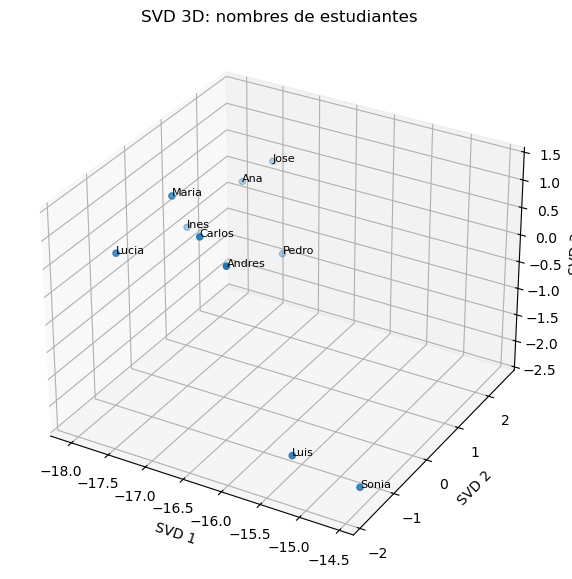

In [25]:
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(T3[:,0],T3[:,1],T3[:,2])
for i, nombre in enumerate(nombres):
    ax.text(T3[i,0],T3[i,1],T3[i,2],nombre,fontsize=8)
ax.set_xlabel("SVD 1"); ax.set_ylabel("SVD 2"); ax.set_zlabel("SVD 3")
ax.set_title("SVD 3D: nombres de estudiantes")
plt.show()

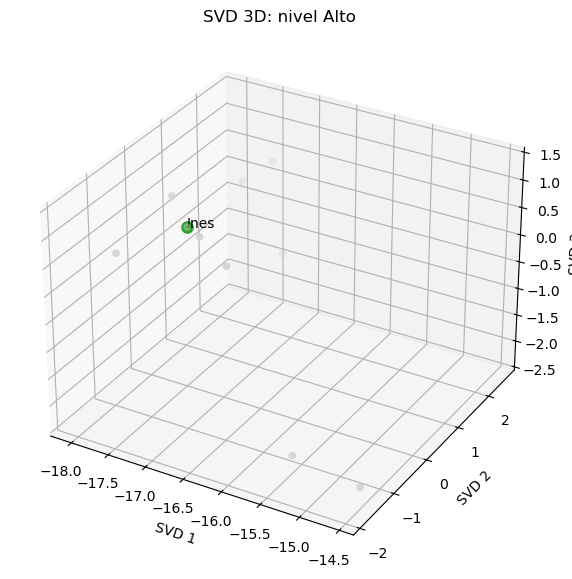

In [26]:
fig = plt.figure(figsize=(9,7))
ax3d = fig.add_subplot(111, projection="3d")
ax3d.scatter(T3[:,0],T3[:,1],T3[:,2],color="lightgray")
for i, nombre in enumerate(nombres):
    if etiquetas.iloc[i] == "Alto":
        ax3d.scatter(T3[i,0],T3[i,1],T3[i,2],color="tab:green",s=65)
        ax3d.text(T3[i,0],T3[i,1],T3[i,2],nombre)
ax3d.set_xlabel("SVD 1"); ax3d.set_ylabel("SVD 2"); ax3d.set_zlabel("SVD 3")
ax3d.set_title("SVD 3D: nivel Alto")
plt.show()

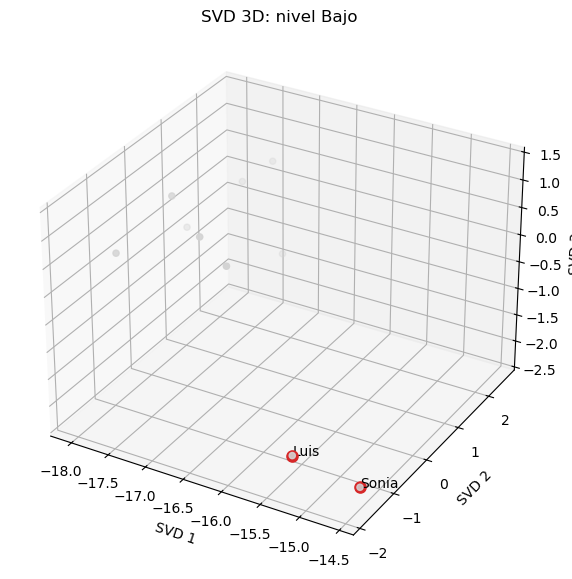

In [28]:
fig = plt.figure(figsize=(9,7))
ax3d = fig.add_subplot(111, projection="3d")
ax3d.scatter(T3[:,0],T3[:,1],T3[:,2],color="lightgray")
for i, nombre in enumerate(nombres):
    if etiquetas.iloc[i] == "Bajo":
        ax3d.scatter(T3[i,0],T3[i,1],T3[i,2],color="tab:red",s=65)
        ax3d.text(T3[i,0],T3[i,1],T3[i,2],nombre)
ax3d.set_xlabel("SVD 1"); ax3d.set_ylabel("SVD 2"); ax3d.set_zlabel("SVD 3")
ax3d.set_title("SVD 3D: nivel Bajo")
plt.show()

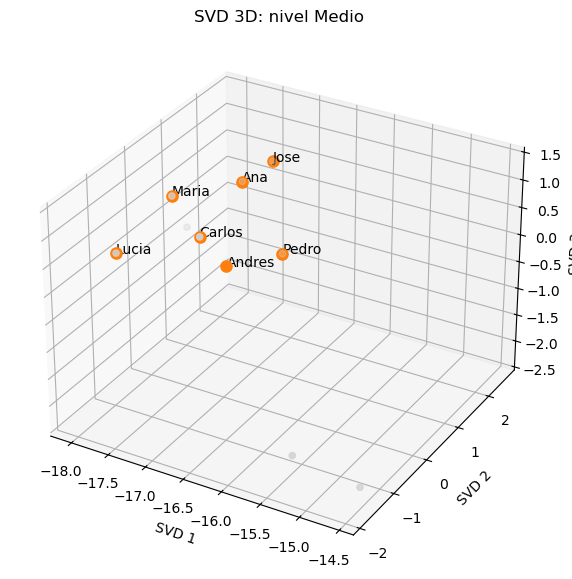

In [29]:
fig = plt.figure(figsize=(9,7))
ax3d = fig.add_subplot(111, projection="3d")
ax3d.scatter(T3[:,0],T3[:,1],T3[:,2],color="lightgray")
for i, nombre in enumerate(nombres):
    if etiquetas.iloc[i] == "Medio":
        ax3d.scatter(T3[i,0],T3[i,1],T3[i,2],color="tab:orange",s=65)
        ax3d.text(T3[i,0],T3[i,1],T3[i,2],nombre)
ax3d.set_xlabel("SVD 1"); ax3d.set_ylabel("SVD 2"); ax3d.set_zlabel("SVD 3")
ax3d.set_title("SVD 3D: nivel Medio")
plt.show()

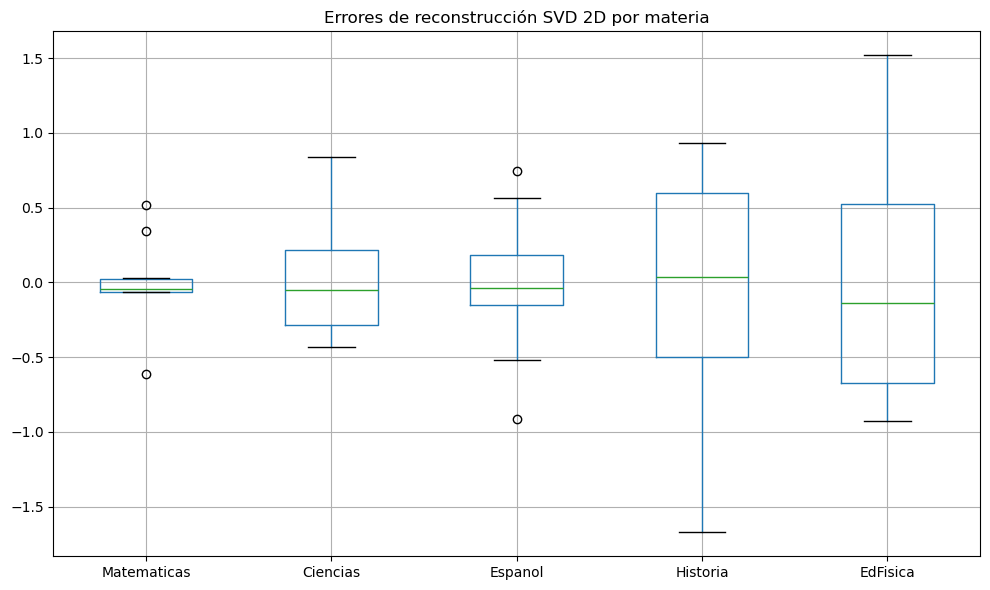

In [30]:
Error2 = B - AReduced2
dfError2 = pd.DataFrame(Error2, index=nombres, columns=materias)
plt.figure(figsize=(10,6))
dfError2.boxplot()
plt.title("Errores de reconstrucción SVD 2D por materia")
plt.tight_layout(); plt.show()

In [31]:
print("Errores promedio con signo por materia (2D):")
print(dfError2.mean())
print("Error cuadrático medio global (2D):",np.mean(Error2**2))

Errores promedio con signo por materia (2D):
Matematicas   -0.000020
Ciencias       0.013261
Espanol       -0.019478
Historia      -0.024507
EdFisica       0.033060
dtype: float64
Error cuadrático medio global (2D): 0.3373844951127626


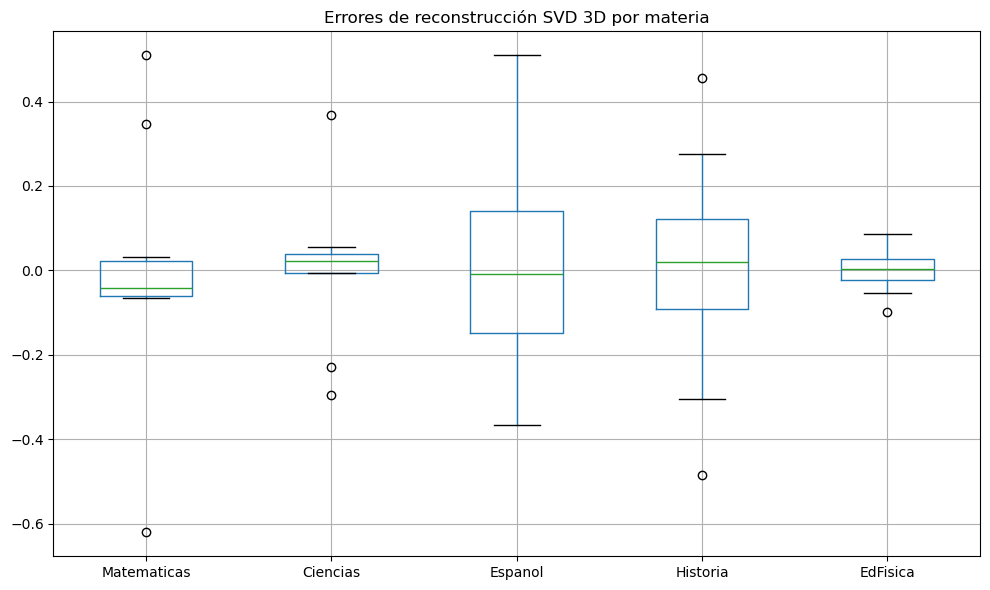

Error cuadrático medio global (3D): 0.04773164122076432


In [32]:
Error3 = B - AReduced3
dfError3 = pd.DataFrame(Error3, index=nombres, columns=materias)
plt.figure(figsize=(10,6))
dfError3.boxplot()
plt.title("Errores de reconstrucción SVD 3D por materia")
plt.tight_layout();plt.show()
print("Error cuadrático medio global (3D):",np.mean(Error3**2))

In [40]:
# Comparación de la calidad de reconstrucción (SVD sin centrar)
energia = s**2 / np.sum(s**2)
print("Porcentaje de energía de los valores singulares:", np.round(100*energia,2))
print("Energía acumulada 2D:",round(100*sum(energia[:2]),2),"%")
print("Energía acumulada 3D:",round(100*sum(energia[:3]),2),"%")
print("ECM SVD 2D:",np.mean(Error2**2))
print("ECM SVD 3D:",np.mean(Error3**2))

Porcentaje de energía de los valores singulares: [9.842e+01 1.000e+00 5.000e-01 8.000e-02 1.000e-02]
Energía acumulada 2D: 99.41 %
Energía acumulada 3D: 99.92 %
ECM SVD 2D: 0.3373844951127626
ECM SVD 3D: 0.04773164122076432


### Comparación con PCA

In [34]:
# PCA convencional centra las variables; por eso puede diferir del SVD aplicado a A sin centrar.
pca = PCA(n_components=3)
P = pca.fit_transform(estudiantes)
print("Varianza explicada PCA:",np.round(100*pca.explained_variance_ratio_,2))
print("Varianza acumulada PCA 2D:",round(100*sum(pca.explained_variance_ratio_[:2]),2),"%")
print("Varianza acumulada PCA 3D:",round(100*sum(pca.explained_variance_ratio_[:3]),2),"%")

Varianza explicada PCA: [61.14 31.35  4.73]
Varianza acumulada PCA 2D: 92.49 %
Varianza acumulada PCA 3D: 97.22 %


### PCA 2D con estudiantes

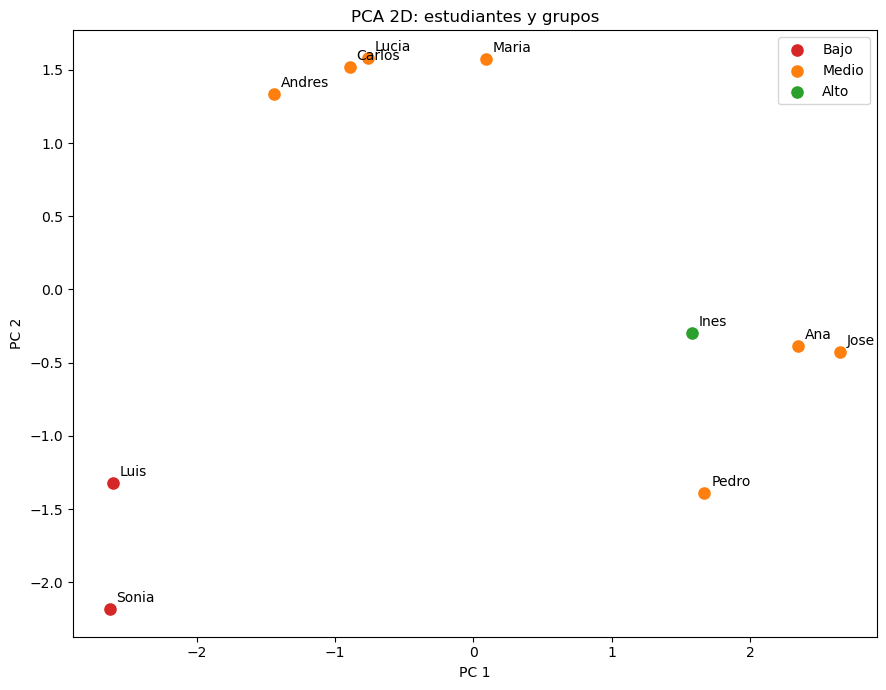

In [35]:
fig, ax = plt.subplots(figsize=(9,7))
for grupo in ["Bajo","Medio","Alto"]:
    mask = etiquetas.to_numpy()==grupo
    ax.scatter(P[mask,0], P[mask,1], color=colores[grupo],label=grupo,s=65)
for i,nombre in enumerate(nombres):
    ax.annotate(nombre,(P[i,0],P[i,1]),xytext=(5,5),textcoords="offset points")
ax.set_xlabel("PC 1");ax.set_ylabel("PC 2");ax.set_title("PCA 2D: estudiantes y grupos");ax.legend()
plt.tight_layout();plt.show()

### PCA 3D con estudiantes

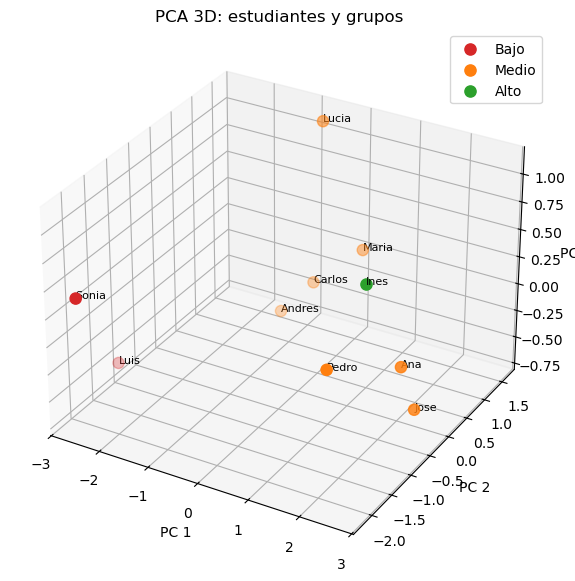

In [36]:
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection="3d")
for grupo in ["Bajo","Medio","Alto"]:
    mask = etiquetas.to_numpy()==grupo
    ax.scatter(P[mask,0],P[mask,1],P[mask,2],color=colores[grupo],label=grupo,s=65)
for i,nombre in enumerate(nombres):
    ax.text(P[i,0],P[i,1],P[i,2],nombre,fontsize=8)
ax.set_xlabel("PC 1");ax.set_ylabel("PC 2");ax.set_zlabel("PC 3")
ax.set_title("PCA 3D: estudiantes y grupos");ax.legend()
plt.show()